# Dispersion and analytical Gaussian propagation

For $g=0$, each Fourier mode acquires a quadratic phase. An initially real Gaussian has $q=1+i d\xi$ and $u=q^{-1/2}\exp[-\tau^2/(2q)]$.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

Complex-field relative error: 1.1130054348985099e-14


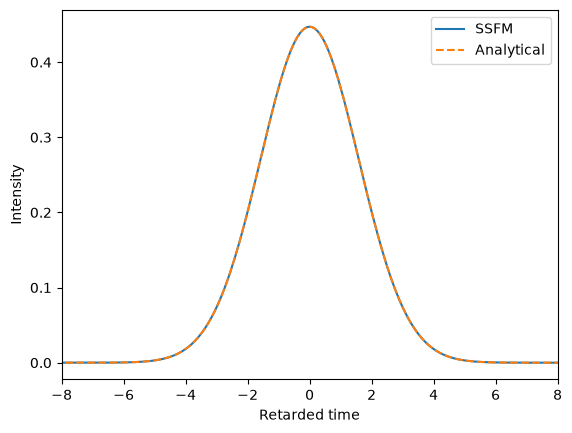

In [2]:
from optics_portfolio.fiber import grid, propagate, relative_error
from optics_portfolio.validation import gaussian_exact
t, _ = grid(512, 40)
field = propagate(np.exp(-t*t/2), t, 2, 40, g=0)[1][-1]
exact = gaussian_exact(t, 2)
print("Complex-field relative error:", relative_error(field, exact))
plt.plot(t, abs(field)**2, label="SSFM")
plt.plot(t, abs(exact)**2, "--", label="Analytical")
plt.xlim(-8, 8); plt.xlabel("Retarded time"); plt.ylabel("Intensity"); plt.legend(); plt.show()

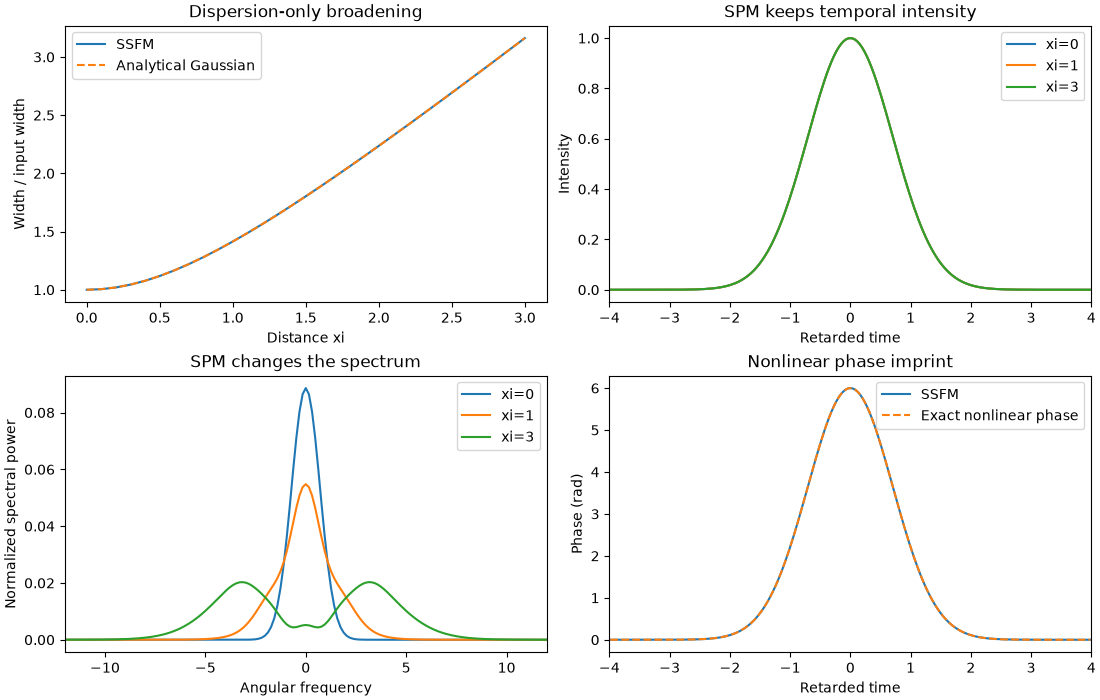

In [3]:
display(Image(filename=str(PROJECT / "results/dispersion_spm.png")))

## Interpret and extend

Explain why temporal broadening can occur without changing the spectral intensity. Repeat with d=-1 and compare intensity and complex phase separately.

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.